In [1]:
import sys
import qiskit
import qiskit_aer
import matplotlib

print("=" * 45)
print("       QISKIT ENVIRONMENT INFORMATION")
print("=" * 45)

print("Python Version:", sys.version.split()[0])
print("Python Executable:", sys.executable)
print("Qiskit Version:", qiskit.__version__)
print("Qiskit Aer Version:", qiskit_aer.__version__)
print("Matplotlib Version:", matplotlib.__version__)

print("\nEnvironment verification completed!")

       QISKIT ENVIRONMENT INFORMATION
Python Version: 3.11.4
Python Executable: e:\Qiskit Ready\.venv\Scripts\python.exe
Qiskit Version: 2.6.2
Qiskit Aer Version: 0.18.2
Matplotlib Version: 3.11.2

Environment verification completed!


# 1. Introduction to Quantum Circuits

A quantum circuit is a sequence of quantum gates applied to qubits.

A qubit can exist in a superposition of the computational basis states |0⟩ and |1⟩.

We use Qiskit to construct, visualize and simulate quantum circuits.

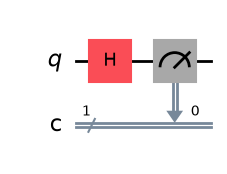

In [2]:
from qiskit import QuantumCircuit

# Create a circuit with 1 qubit and 1 classical bit
qc = QuantumCircuit(1, 1)

# Apply the Hadamard gate
qc.h(0)

# Measure the qubit
qc.measure(0, 0)

# Display the circuit
display(qc.draw(output="mpl"))

# 2. Basic Quantum Gates

Quantum gates manipulate the state of qubits.

- X Gate: Bit-flip gate. Converts |0⟩ to |1⟩ and vice versa.
- Y Gate: Bit and phase-flip gate.
- Z Gate: Phase-flip gate. Changes the phase of |1⟩.
- H Gate: Hadamard gate. Creates an equal superposition from |0⟩.

X Gate


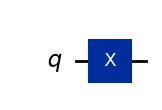

Y Gate


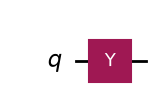

Z Gate


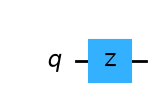

Hadamard Gate


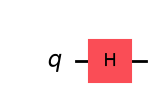

In [3]:
from qiskit import QuantumCircuit

gates = {
    "X Gate": "x",
    "Y Gate": "y",
    "Z Gate": "z",
    "Hadamard Gate": "h"
}

for gate_name, gate_operation in gates.items():
    qc = QuantumCircuit(1)

    getattr(qc, gate_operation)(0)

    print(gate_name)
    display(qc.draw(output="mpl"))

# 3. Quantum Circuit Simulation

A quantum simulator allows us to execute quantum circuits without requiring physical quantum hardware.

The Hadamard gate transforms |0⟩ into an equal superposition:

|+⟩ = (|0⟩ + |1⟩) / √2

When measured, the qubit has an equal probability of producing 0 or 1.

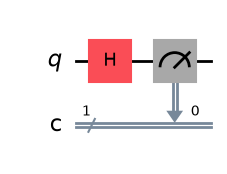

Measurement Results: {'0': 505, '1': 495}


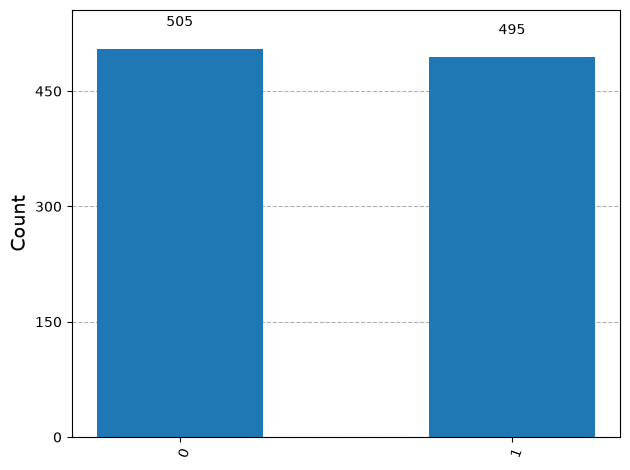

In [11]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Create a one-qubit circuit
qc = QuantumCircuit(1, 1)

# Apply Hadamard gate
qc.h(0)

# Measure the qubit
qc.measure(0, 0)

# Visualize circuit
display(qc.draw(output="mpl"))

# Initialize simulator
simulator = AerSimulator()

# Compile and execute
compiled_circuit = transpile(qc, simulator)
result = simulator.run(compiled_circuit, shots=1000).result()

# Get measurement counts
counts = result.get_counts()

print("Measurement Results:", counts)

# Plot histogram
display(plot_histogram(counts))

# 4. Quantum Entanglement – Bell State

Quantum entanglement is a phenomenon where two or more qubits share a correlated quantum state.

We will create the Bell state:

|Φ⁺⟩ = (|00⟩ + |11⟩) / √2

We use:
1. Hadamard gate (H) on the first qubit.
2. CNOT gate with the first qubit as control and the second as target.

This creates an entangled state.

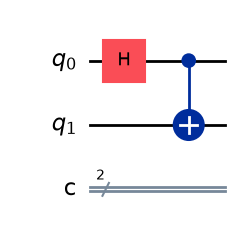

In [12]:
from qiskit import QuantumCircuit

# Create a 2-qubit circuit
qc = QuantumCircuit(2, 2)

# Apply Hadamard gate to first qubit
qc.h(0)

# Apply CNOT gate
qc.cx(0, 1)

# Display the circuit
display(qc.draw(output="mpl"))

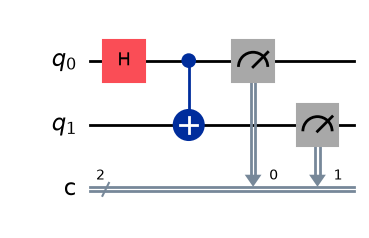

Bell State Measurement Results: {'11': 526, '00': 474}


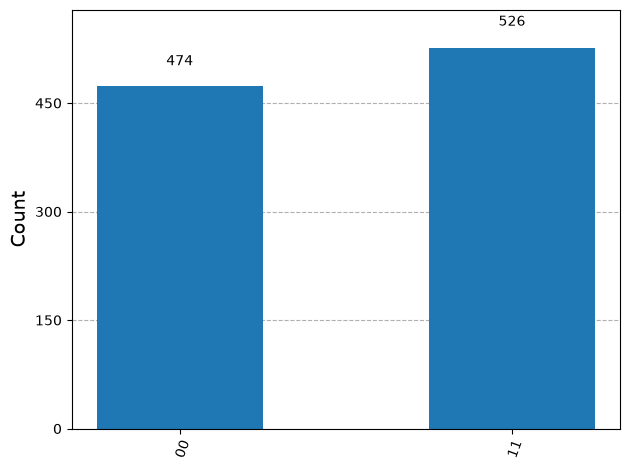

In [13]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Create a 2-qubit circuit with 2 classical bits
qc = QuantumCircuit(2, 2)

# Create Bell state
qc.h(0)
qc.cx(0, 1)

# Measure both qubits
qc.measure([0, 1], [0, 1])

# Display circuit
display(qc.draw(output="mpl"))

# Simulate the circuit
simulator = AerSimulator()
compiled = transpile(qc, simulator)

result = simulator.run(compiled, shots=1000).result()
counts = result.get_counts()

# Display results
print("Bell State Measurement Results:", counts)
display(plot_histogram(counts))

# 5. Conclusion

In this experiment, we successfully:

1. Configured and verified the Qiskit environment.
2. Created quantum circuits using Qiskit.
3. Implemented basic quantum gates.
4. Simulated a Hadamard gate.
5. Created an entangled Bell state using H and CNOT gates.
6. Measured the entangled qubits using Qiskit Aer.
7. Visualized measurement results using a histogram.

The Bell-state simulation produced only 00 and 11 outcomes,
demonstrating the correlation between the two entangled qubits.

All experiments were performed using the local Qiskit Aer simulator.